# Smash History: Tournament Activity, Characters, and Competitive Players

**Team:** Christian Ohlsson and Trevor Scofield  
**Project scope:** competitive Super Smash Bros. history, with character-level analysis from recorded Ultimate games  
**Visualization count:** 7 (team of two)  
**Core environment:** Python, Matplotlib, Jupyter Notebook

This report builds on the team proposal and the `tournament_info.csv` / `sets.csv` files. It translates the proposal's three questions into a reproducible analysis and seven figures. The largest CSV is several gigabytes, so the companion analysis module reads rows as a stream rather than loading the source into memory.

## Project questions and expected users

The proposal asks how competitive activity changes over time, how character selection relates to results, and which players have the most recorded wins. We focus on three audiences: players choosing characters, tournament/community analysts interpreting the metagame, and researchers studying competitive play.

1. **Historical activity:** When are tournaments and recorded sets concentrated?
2. **Character metagame:** Which characters are used most, how do their observed game win rates compare with usage, and which character matchups are represented?
3. **Player careers:** Which recorded player IDs have the most set wins, and how do top players' most-used characters differ across earlier and later periods?

These are descriptive questions. The figures do not establish that a character causes a win or that a character is intrinsically stronger: player skill, matchup choice, bracket level, reporting coverage, and tournament size are not fully controlled.

## Data, fields, and preparation

### Inputs

-'https://www.kaggle.com/datasets/thomasdubail/super-smash-bros-database?select=ultimate_player_database' is the database where the data can be found. to large to upload into github where we colab
- `tournament_info/tournament_info.csv`: one row per tournament; includes `key`, `game`, `start`, location, entrant count, and final placements. `start` is a Unix timestamp and `key` links to sets.
- `tournament_info/sets.csv`: one row per tournament set; includes `tournament_key`, `winner_id`, participant IDs, scores, and `game_data`.
- `game_data` is JSON. Each array item is an individual game, with fields such as `winner_id`, `loser_id`, `winner_char`, `loser_char`, and `stage`. Character win rates count individual games (not tournament sets).

### Transformations

1. Read only tournament keys and start years from the tournament file, creating a small join lookup.
2. Stream the sets file and join each set to its tournament year using `tournament_key`.
3. Parse per-game JSON; count each winner/loser character appearance once and increment a win only for `winner_char`.
4. Count head-to-head wins as `(winner_char, loser_char)`, and player set wins from `winner_id`.
5. Define earlier/later eras by the midpoint of the observed tournament-year range. For the alluvial view, compare each qualifying top player's modal character in each era.

### Limits to keep in mind

- Empty `game_data` rows cannot contribute character picks or matchup results; coverage varies across tournaments.
- Player identifiers are mixed IDs and handles. These files do not provide a reliable public player-name lookup.
- Character win percentages are raw observed game win rates. They are vulnerable to player-skill and matchup confounding; small samples are filtered from the scatter plot.
- Earlier/later character choices are descriptive and can reflect sparse reporting, a player's career stage, or format changes.
- The final observed tournament year (2024 here) may be incomplete. A decrease at the end of the timeline can reflect a partial export window rather than a real decline in play.
- The annual character stack is normalized to shares. Early years with very few records still sum to 100%, so compare those shapes cautiously and check record counts in Figures 1 and 2.
- The proposal cites a Kaggle dataset page. Retain that attribution and download the same source files for reproduction; the CSVs are not copied into the submission package because of their size.

## Reproducibility and LLM prompt strategy

The visualizations were produced in Python with Matplotlib. The LLM workflow was iterative: start with the available tournament columns, inspect the supplementary set-level data, discover that `game_data` contains per-game character outcomes, then refine the analysis around the assignment's seven-figure requirement. The conversation prompts below are reproduced verbatim from the project workflow; the code is maintained in the companion `smash_history_analysis.py` file and imported by the cells below.

### Prompt sequence

1. “here is the result I got from running the bash command: usage: visualize_tournaments.py [-h] [-o OUTPUT] [--top TOP] [csv_file] visualize_tournaments.py: error: field larger than field limit (131072)”

### Re-run

Place both CSV files in `tournament_info/` beside this notebook and `smash_history_analysis.py`. Install Python 3.10+, Matplotlib, and Jupyter, then run all cells from top to bottom. Source row streaming avoids loading either full CSV into RAM. The figure cells save PNG copies under `output/smash_history_figures/` as well as embedding them in this notebook.

```bash
python -m pip install matplotlib jupyter
jupyter notebook smash_history_report.ipynb
```

## Seven visualization plan

| # | Visualization | Proposal feature | Main reading |
|---|---|---|---|
| 1 | Tournament starts by year | Performance over time | Event activity and coverage |
| 2 | Tournament sets by year and game | Performance over time | Competitive match volume |
| 3 | Character appearances by year | Character use and success | Popularity shifts in the metagame |
| 4 | Character usage vs. win-rate scatter | Character use and success | Popularity compared with recorded outcomes |
| 5 | Split-cell matchup matrix (custom) | Character use and success | Directional head-to-head results |
| 6 | Top players by set wins | Player dominance | Most recorded tournament-set wins |
| 7 | Player-character alluvial view (custom) | Player character choices | Modal character by era for qualified top players |

Figures 5 and 7 directly map data to custom visual encodings in Matplotlib (split triangles and flow ribbons). All seven plots have complete source in `smash_history_analysis.py`; this notebook calls each plotting function and records the rendered output.

In [ ]:
from pathlib import Path
from IPython.display import display
 import matplotlib.pyplot as plt
 import pickle
 import smash_history_analysis as analysis

# Run this notebook from the project directory. If your files are elsewhere,
# edit these two paths and rerun all cells.
DATA_DIR = Path("tournament_info")
TOURNAMENT_CSV = DATA_DIR / "tournament_info.csv"
SETS_CSV = DATA_DIR / "sets.csv"
FIGURE_DIR = Path("output") / "smash_history_figures"
 FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_FILE = Path("tmp") / "smash_analysis_cache.pkl"

assert TOURNAMENT_CSV.is_file(), f"Missing tournament file: {TOURNAMENT_CSV.resolve()}"
assert SETS_CSV.is_file(), f"Missing sets file: {SETS_CSV.resolve()}"
print("Tournament file:", TOURNAMENT_CSV.resolve())
print("Sets file:", SETS_CSV.resolve())
print("Figure output:", FIGURE_DIR.resolve())

In [1]:
# Full streaming pass through both CSV files. The sets file is about 3.9 GB,
# so this step can take several minutes on a typical laptop.
source_key = analysis.source_fingerprint(TOURNAMENT_CSV, SETS_CSV)
if CACHE_FILE.is_file():
    with CACHE_FILE.open("rb") as cache_stream:
        data = pickle.load(cache_stream)
else:
    data = None
if data is not None and data.get("source_fingerprint") == source_key:
    print(f"Loaded cached aggregates from {CACHE_FILE.resolve()}")
else:
    data = analysis.analyze_data(TOURNAMENT_CSV, SETS_CSV, progress_every=250_000)
    CACHE_FILE.parent.mkdir(parents=True, exist_ok=True)
    with CACHE_FILE.open("wb") as cache_stream:
        pickle.dump(data, cache_stream, protocol=pickle.HIGHEST_PROTOCOL)
years = sorted(data["events_by_year"])
print(f"Tournament rows: {data['total_events']:,}")
print(f"Set rows: {data['total_sets']:,}")
print(f"Sets joined to a tournament start year: {data['linked_sets']:,} ({data['linked_sets']/data['total_sets']:.1%})")
print(f"Sets with character data: {data['sets_with_character_data']:,}")
print(f"Individual games with both characters recorded: {data['games_with_both_characters']:,}")
print(f"Individual games missing one or both characters: {data['games_missing_character']:,}")
print(f"Observed tournament years: {min(years)}–{max(years)}")
print(f"Earlier/later split midpoint: {data['midpoint_year']:.1f}")

Loaded cached aggregates from C:\Users\TJSCO\GithubDesktop\ComputerVisualizationProject\tmp\smash_analysis_cache.pkl
Tournament rows: 177,633
Set rows: 11,000,167
Sets joined to a tournament start year: 11,000,167 (100.0%)
Sets with character data: 3,778,357
Individual games with both characters recorded: 9,878,655
Individual games missing one or both characters: 224,365
Observed tournament years: 2015–2024
Earlier/later split midpoint: 2019.5


## Data coverage check

The character plots use only per-game entries with character values. The report prints the number of joined sets and the number of sets with at least one recorded character. Character outcome counts are game-level; set-winner counts in Figure 6 are set-level. A missing character record is not treated as a loss or a non-use.

In [2]:
top_chars = data["character_uses"].most_common(10)
print("Most-used characters and recorded game win rates:")
for character, appearances in top_chars:
    wins = data["character_wins"][character]
    print(f"  {character:20s} {appearances:>9,} appearances | {wins/appearances:6.1%} wins")

print("\nTop player IDs/handles by recorded set wins:")
for player, wins in data["player_set_wins"].most_common(10):
    print(f"  {player:24s} {wins:>8,} wins")

Most-used characters and recorded game win rates:
  Pokémon Trainer        380,924 appearances |  49.4% wins

Top player IDs/handles by recorded set wins:
  1006473                     8,363 wins
  539670                      6,280 wins
  232730                      5,786 wins
  136534                      5,208 wins
  24025                       5,188 wins
  1051067                     4,959 wins
  1665272                     4,899 wins
  58121                       4,828 wins
  375087                      4,807 wins
  1722276                     4,554 wins


## Visualizations

The following cells render and save all seven figures. Each cell calls one plotting function whose full implementation is in the accompanying source module.

### 1. Tournament activity by year

Shows the number of tournament rows with a usable start date. This is a measure of events present in this dataset, not a complete census of the competitive scene.

**Reproducible source:** `smash_history_analysis.py` → `plot_activity_by_year(data)`.

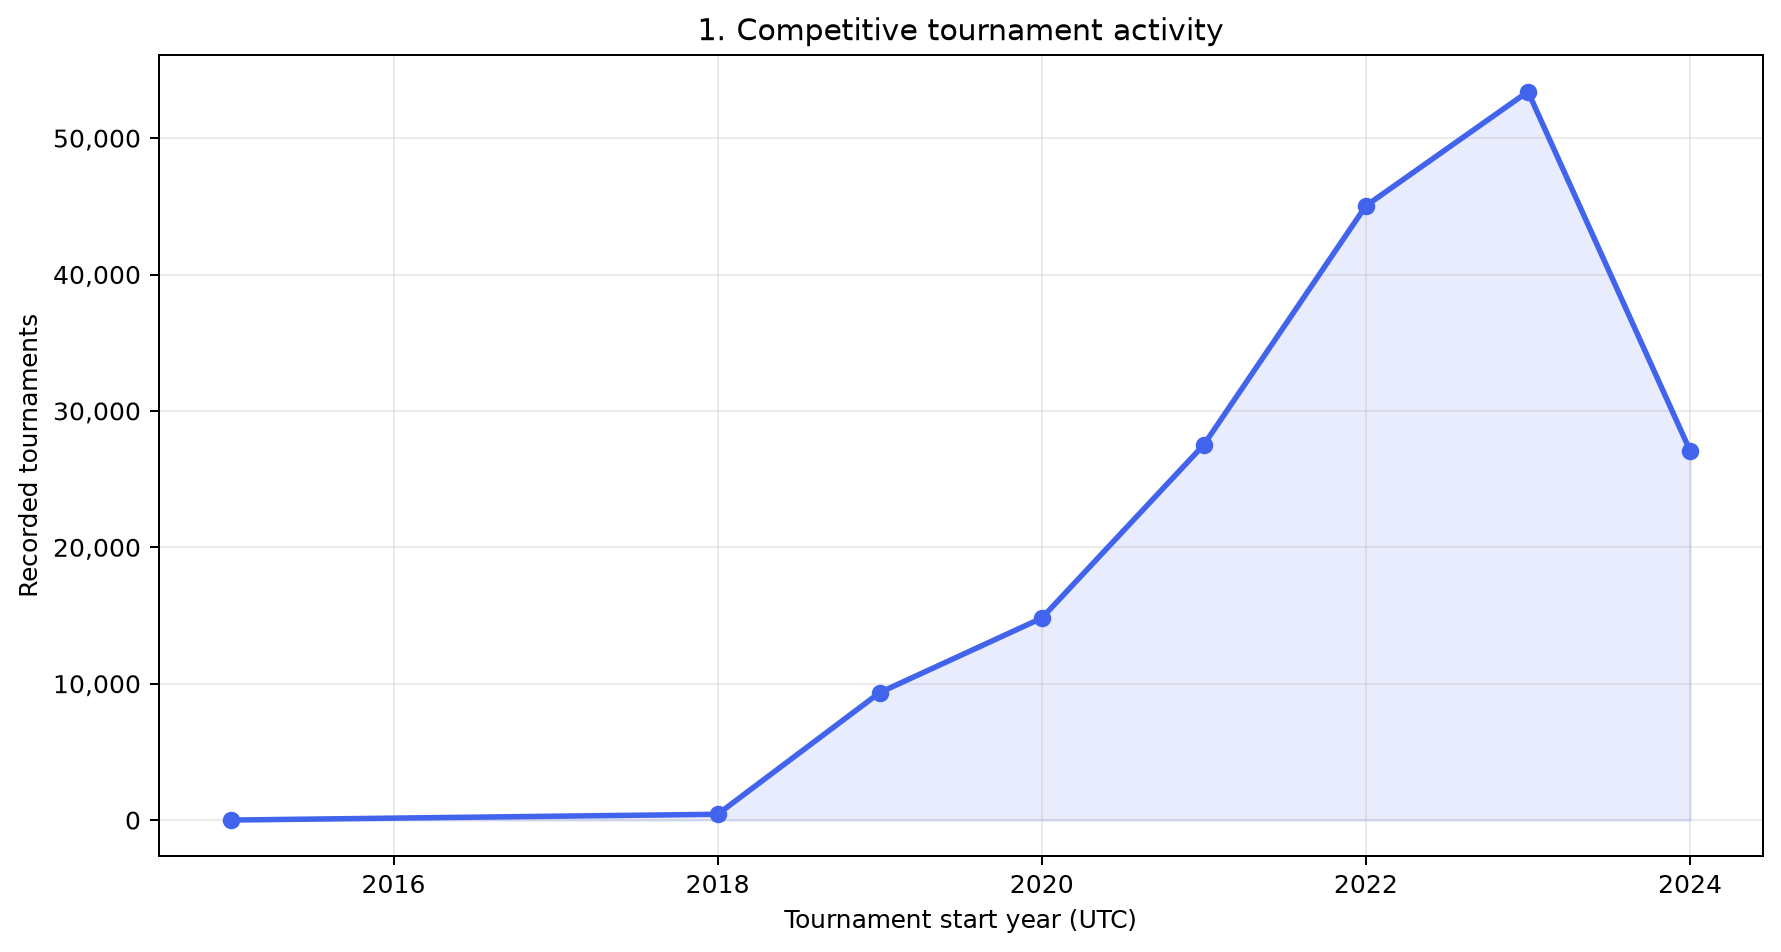

In [3]:
fig = analysis.plot_activity_by_year(data)
fig.savefig(FIGURE_DIR / '01_tournament_activity.png', dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

### 2. Tournament sets by year

Shows matched set rows by tournament year, split across the most represented game labels. This captures match-record volume; coverage and event sizes can change over time.

**Reproducible source:** `smash_history_analysis.py` → `plot_sets_by_year(data)`.

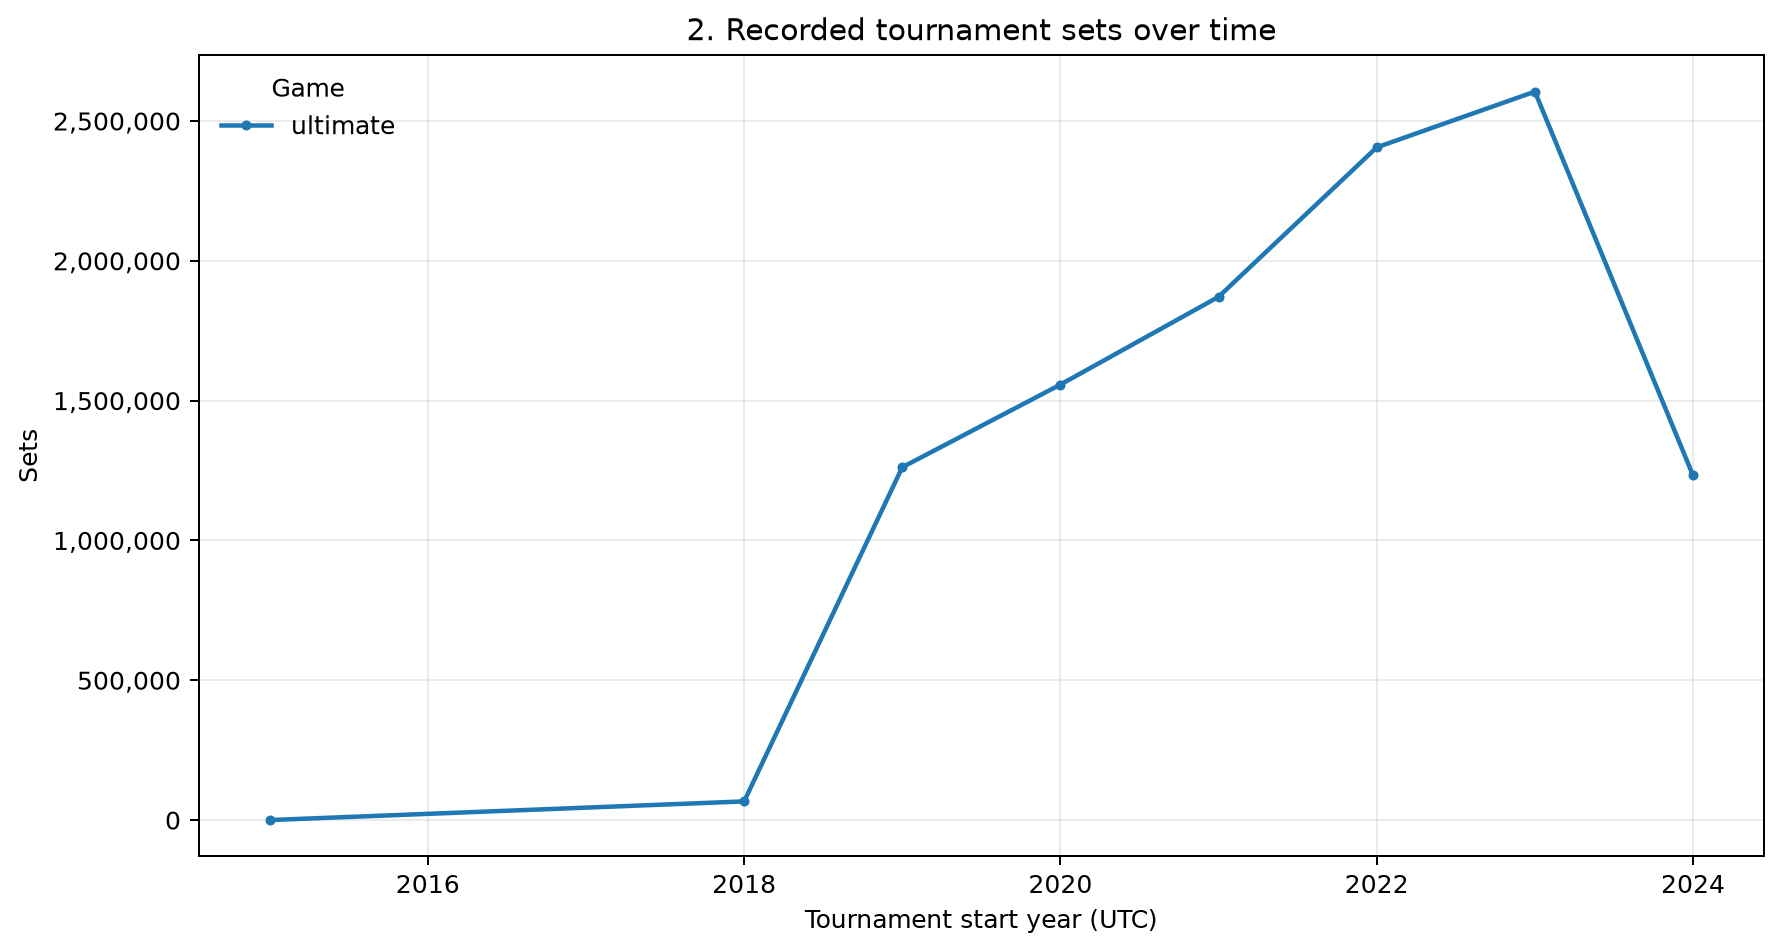

In [4]:
fig = analysis.plot_sets_by_year(data)
fig.savefig(FIGURE_DIR / '02_sets_by_year.png', dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

### 3. Character use across history

Shows the annual share of recorded character appearances for the most-used characters, with remaining characters grouped together. Shares make years with different amounts of reporting easier to compare, but do not correct for missing game_data.

**Reproducible source:** `smash_history_analysis.py` → `plot_character_popularity(data)`.

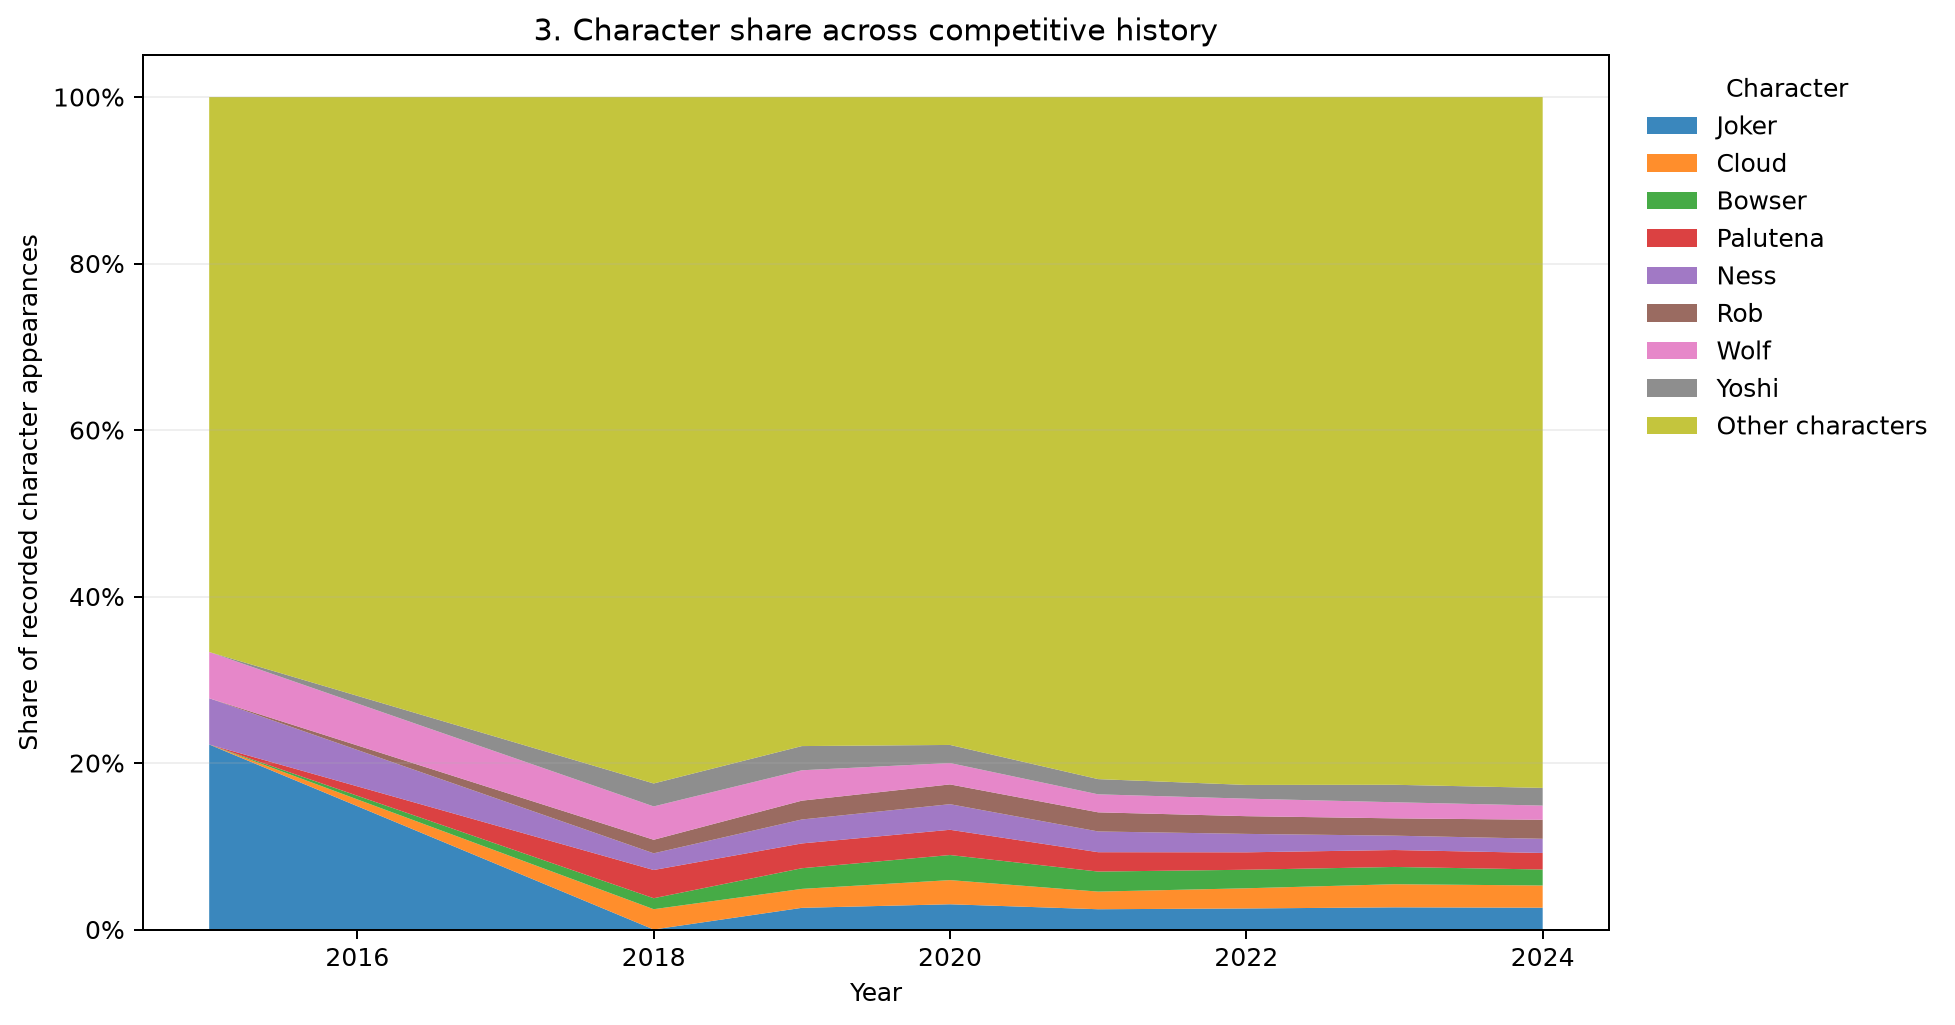

In [5]:
fig = analysis.plot_character_popularity(data)
fig.savefig(FIGURE_DIR / '03_character_popularity.png', dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

### 4. Character usage and win percentage

Each point represents a character. The horizontal axis is game appearances (log scale) and the vertical axis is its share of recorded individual games won. Only characters with at least 25 recorded appearances are shown; labels highlight the most-used characters.

**Reproducible source:** `smash_history_analysis.py` → `plot_character_usage_winrate(data)`.

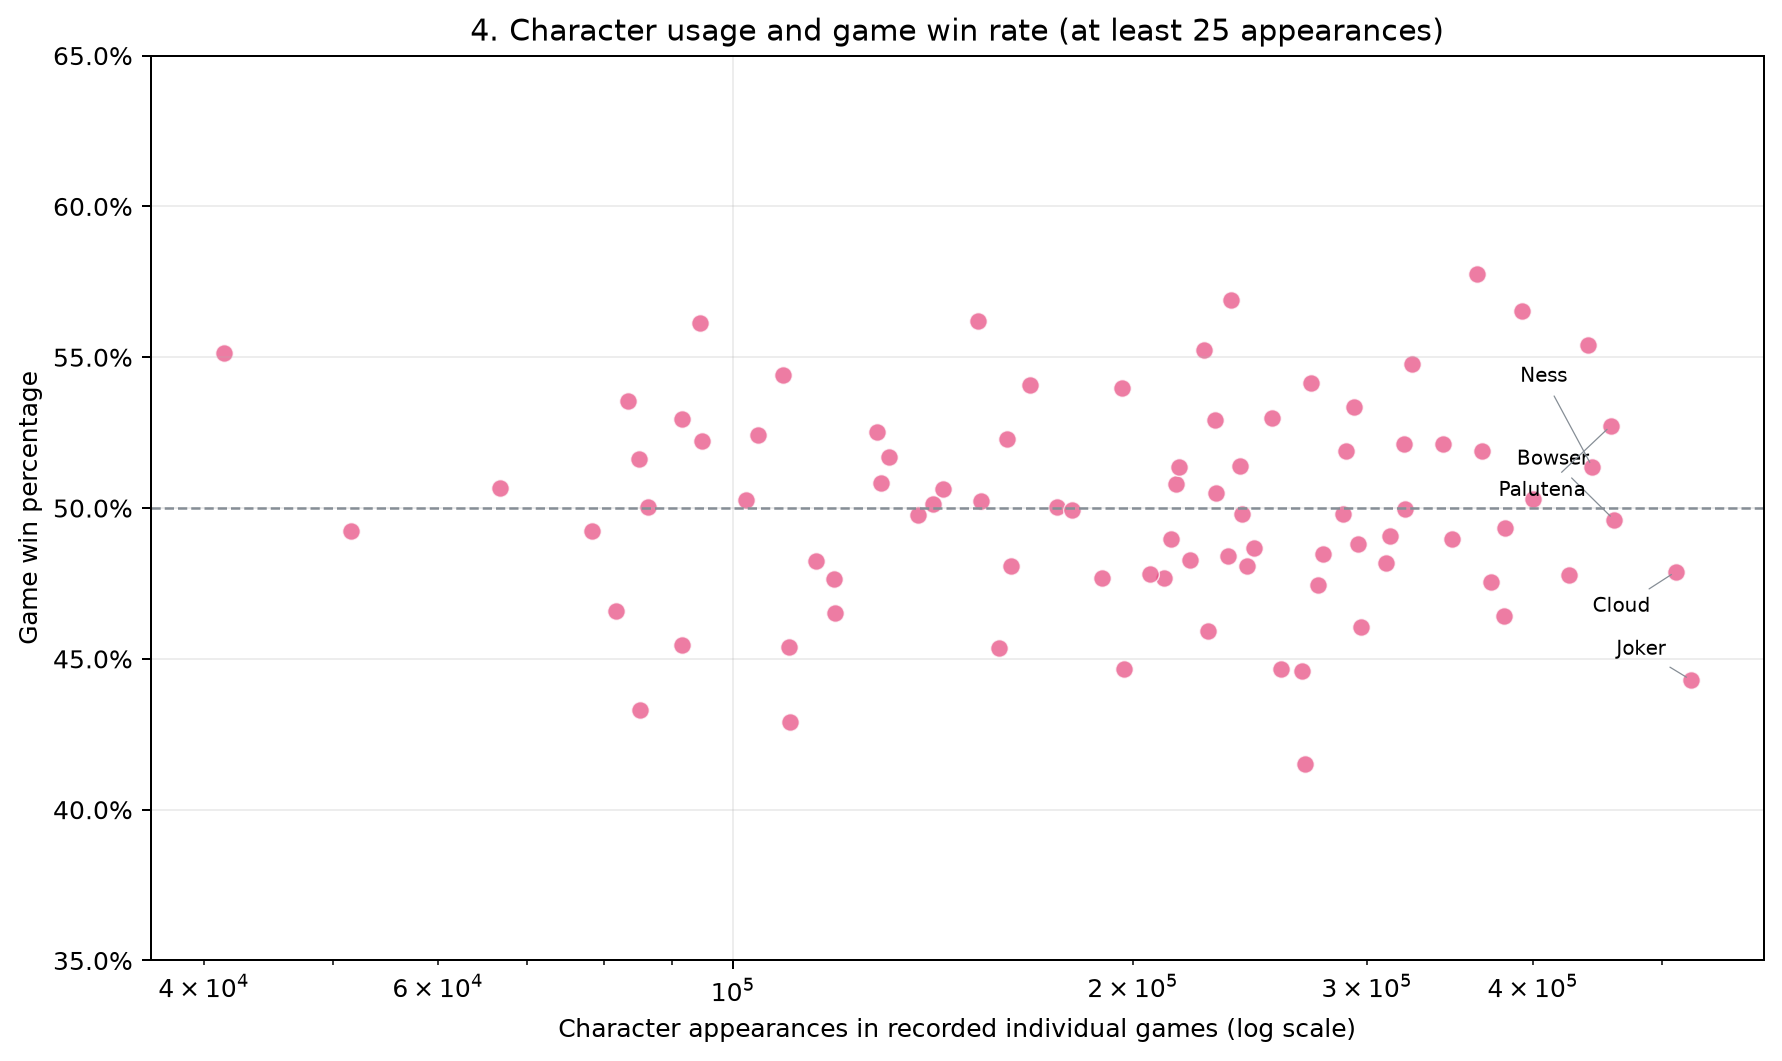

In [6]:
fig = analysis.plot_character_usage_winrate(data)
fig.savefig(FIGURE_DIR / '04_character_usage_winrate.png', dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

### 5. Character matchup matrix (custom visualization)

Each square is split into two triangles. Triangle color encodes the directional share of recorded head-to-head game wins; the number is the total observed matchup count. This custom encoding makes both sides' outcomes visible in one cell. Sparse or absent matchups should not be interpreted as evidence of balance.

**Reproducible source:** `smash_history_analysis.py` → `plot_matchup_triangle(data)`.

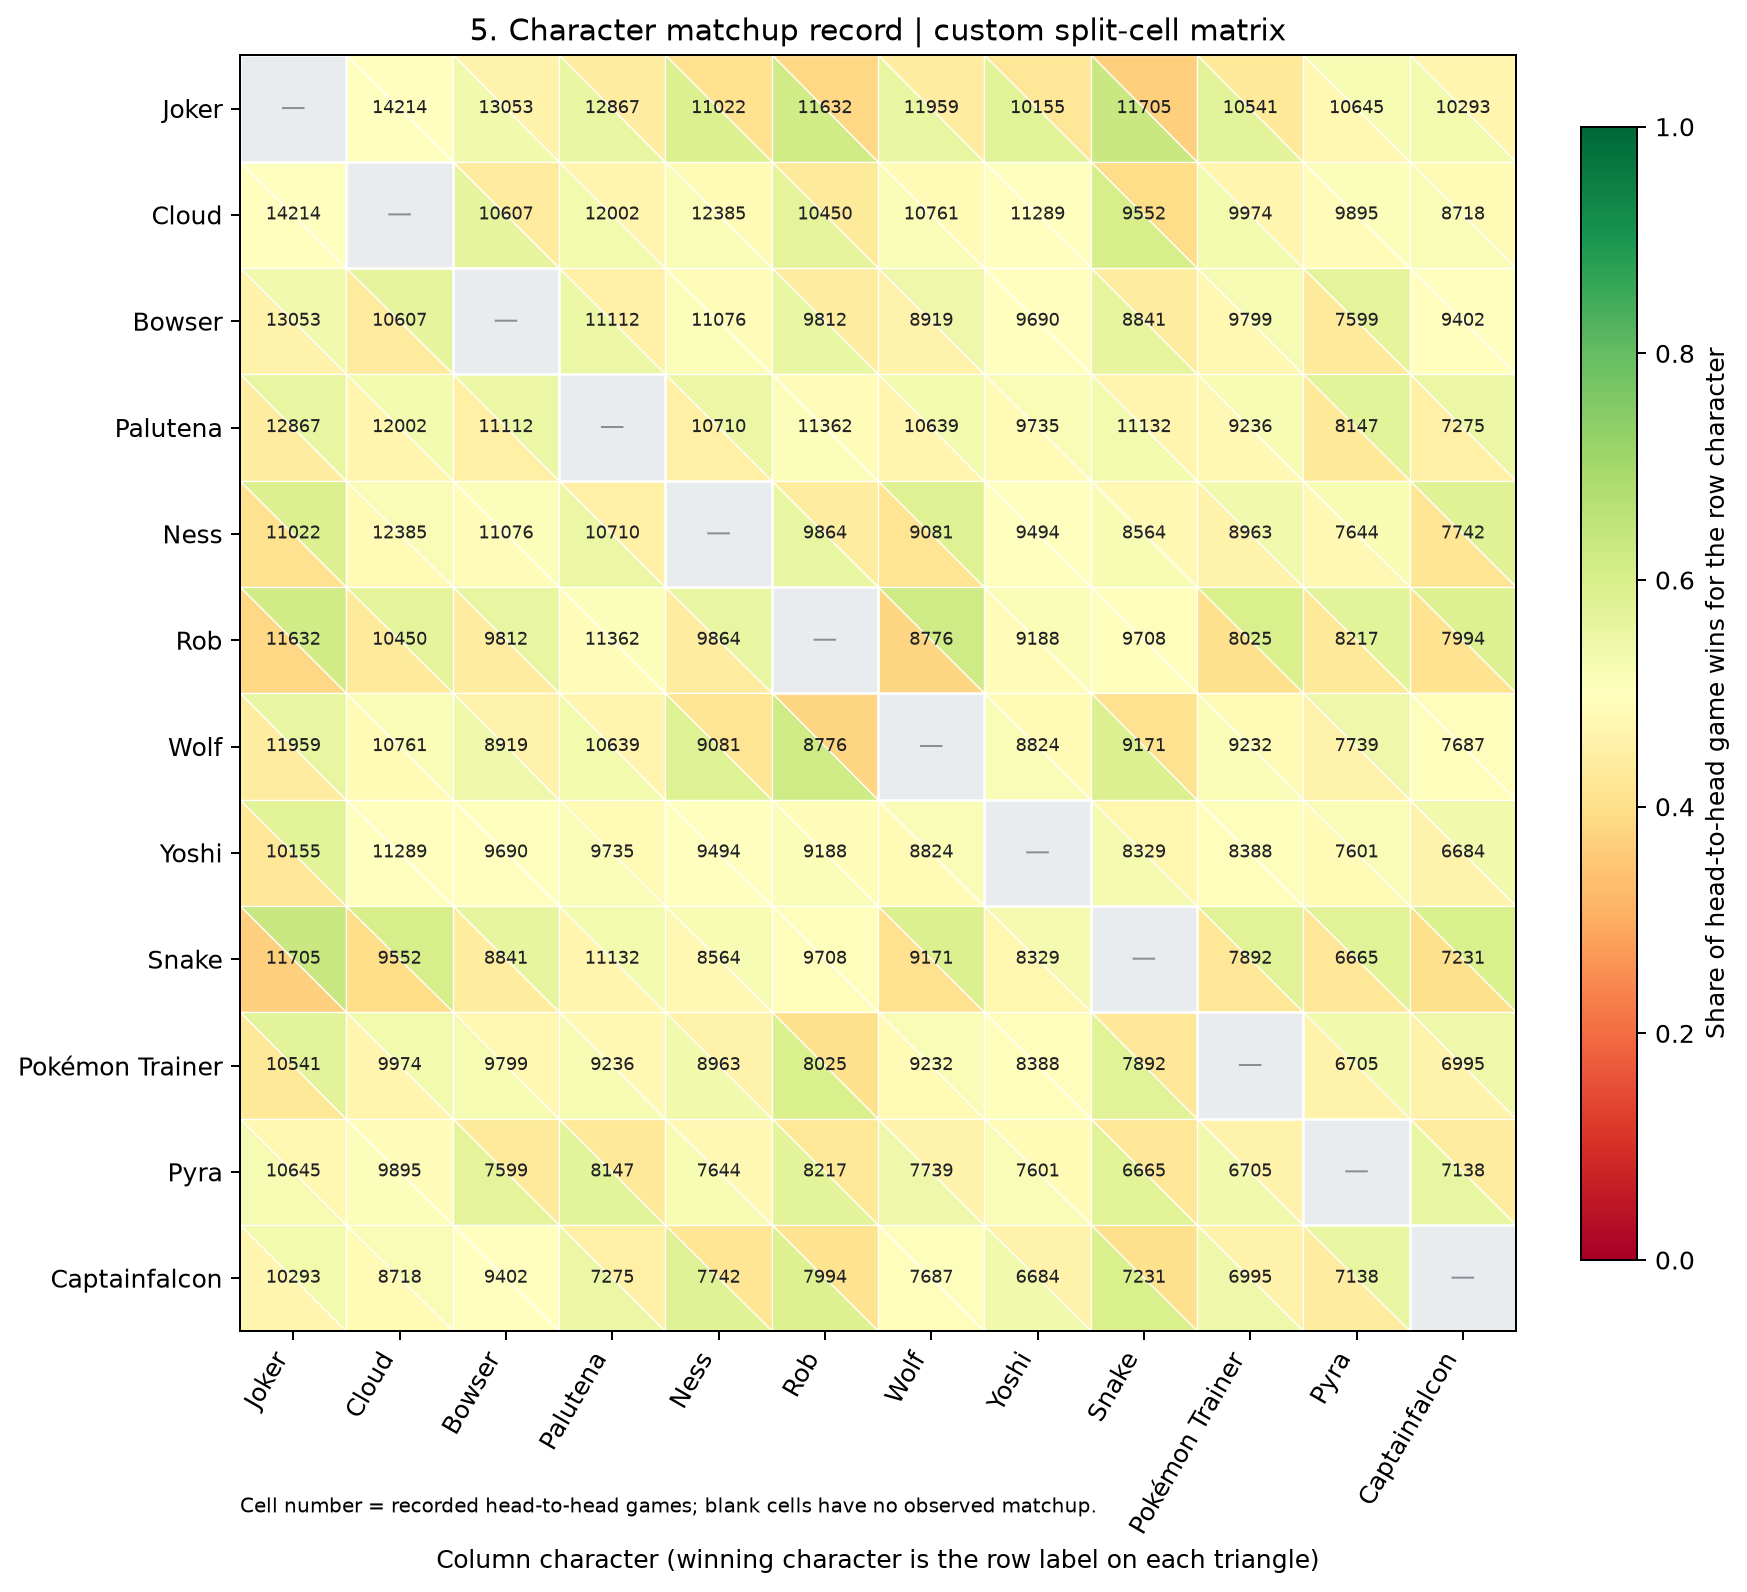

In [7]:
fig = analysis.plot_matchup_triangle(data)
fig.savefig(FIGURE_DIR / '05_matchup_matrix.png', dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

### 6. Players with the most recorded set wins

Ranks winner IDs/handles by the number of set rows where they appear as winner_id. The source does not provide a stable player-name lookup, so labels preserve the recorded identifiers.

**Reproducible source:** `smash_history_analysis.py` → `plot_top_players(data)`.

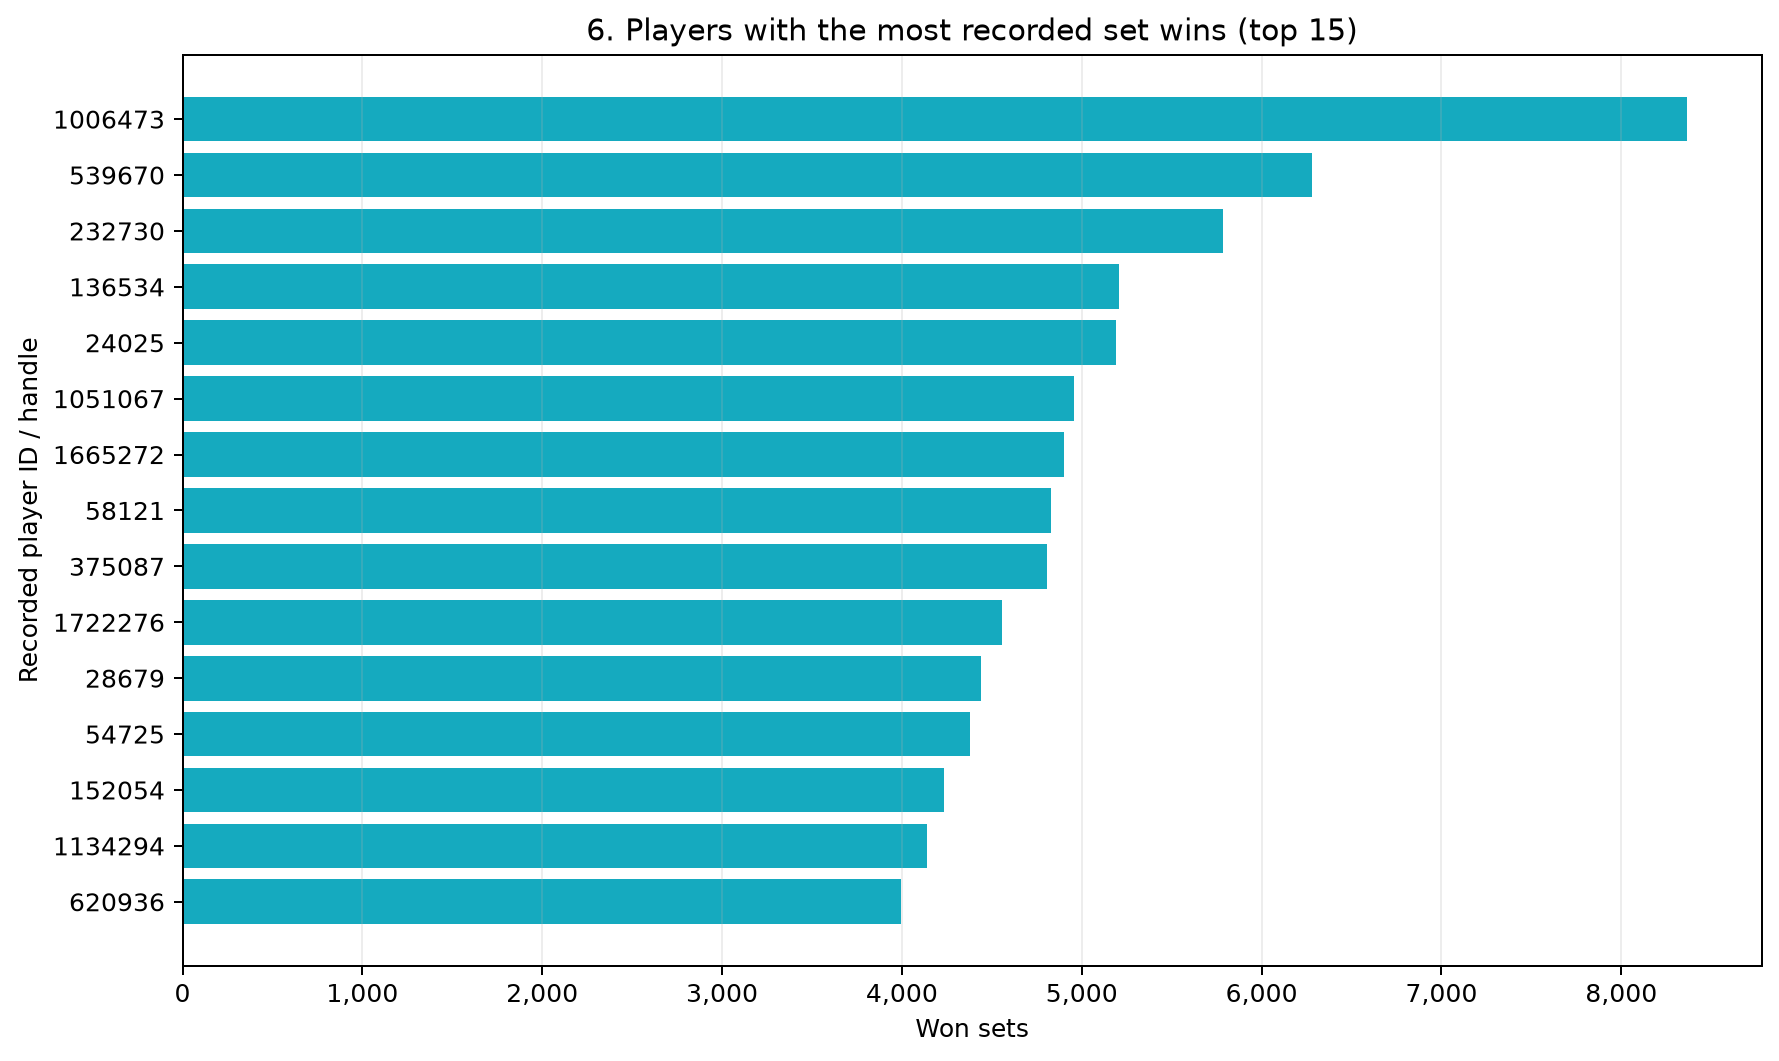

In [8]:
fig = analysis.plot_top_players(data)
fig.savefig(FIGURE_DIR / '06_top_players.png', dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

### 7. Top-player character changes (custom alluvial visualization)

Each ribbon connects a top player's most-used character in the earlier period to their most-used character in the later period. Players are selected from the top 30 by set wins and must have at least 10 character-recorded games in both periods. Ribbon widths represent the number of qualifying players. This is a descriptive proxy for character flexibility, not a complete career history.

**Reproducible source:** `smash_history_analysis.py` → `plot_player_character_flow(data)`.

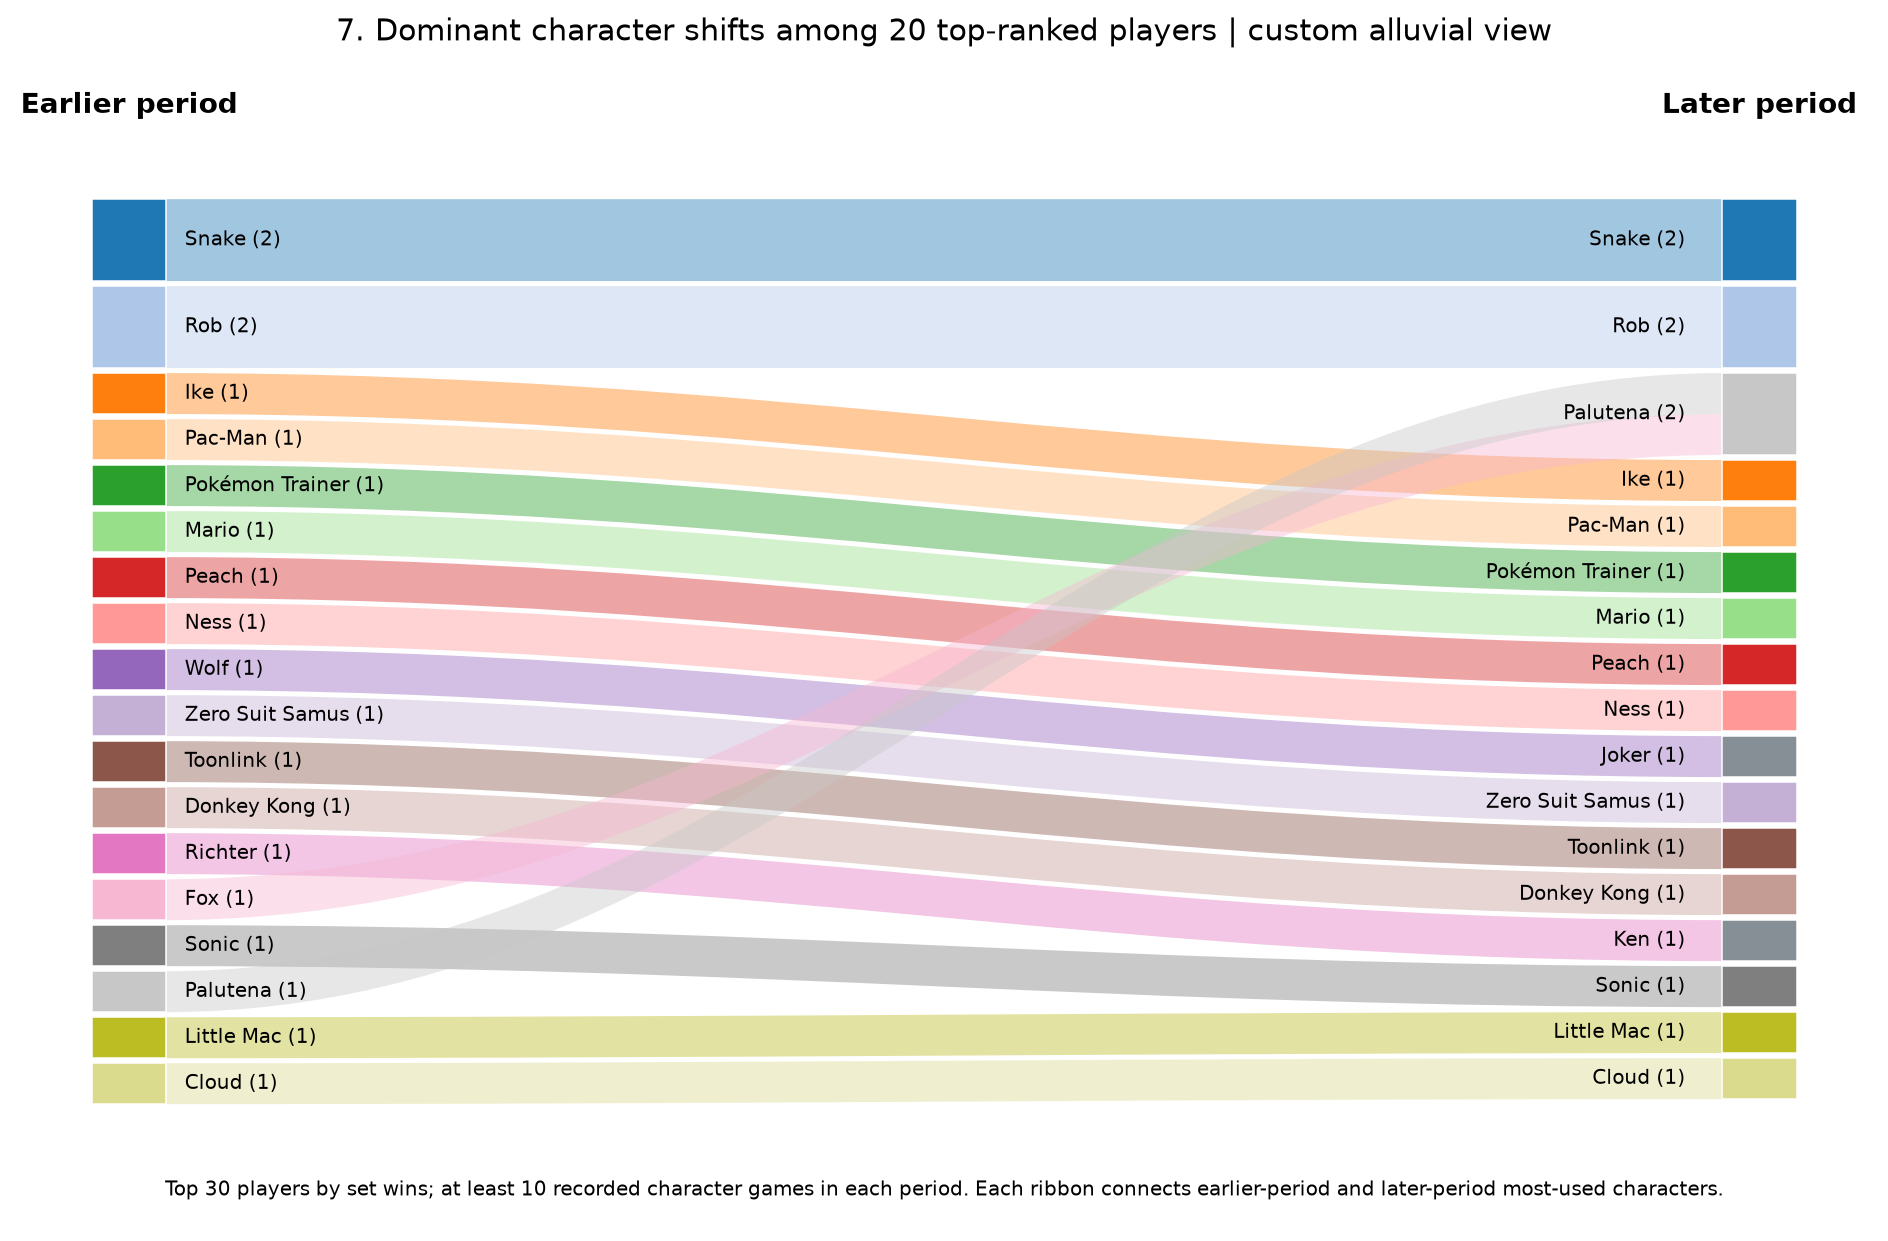

In [9]:
fig = analysis.plot_player_character_flow(data)
fig.savefig(FIGURE_DIR / '07_player_character_flow.png', dpi=180, bbox_inches="tight")
display(fig)
plt.close(fig)

## Data-derived findings to carry into the case studies

This cell writes results from the supplied files into the executed notebook so readers can verify the observations against the seven figures.

In [10]:
years = sorted(data["events_by_year"])
peak_event_year = max(data["events_by_year"], key=data["events_by_year"].get)
peak_event_count = data["events_by_year"][peak_event_year]
top_character, top_character_uses = data["character_uses"].most_common(1)[0] if data["character_uses"] else ("No character data", 0)
top_player, top_player_wins = data["player_set_wins"].most_common(1)[0] if data["player_set_wins"] else ("No winner IDs", 0)
qualified_flows, qualified_players = analysis._main_characters_by_era(data, player_limit=30)
eligible_rates = [(char, data["character_wins"][char] / count, count)
                  for char, count in data["character_uses"].items() if count >= 25]
high_rate = max(eligible_rates, key=lambda x: x[1]) if eligible_rates else None
low_rate = min(eligible_rates, key=lambda x: x[1]) if eligible_rates else None

print(f"Coverage: {data['linked_sets']:,} / {data['total_sets']:,} set rows joined to a dated tournament ({data['linked_sets']/data['total_sets']:.1%}).")
print(f"Tournament records peak in {peak_event_year} ({peak_event_count:,} events in the supplied file).")
print(f"Most-used character: {analysis.character_label(top_character)} ({top_character_uses:,} recorded game appearances).")
if high_rate and low_rate:
    print(f"Among characters with at least 25 appearances, observed rates range from {low_rate[0]} ({low_rate[1]:.1%}, n={low_rate[2]:,}) to {high_rate[0]} ({high_rate[1]:.1%}, n={high_rate[2]:,}).")
print(f"Most frequent set winner ID/handle: {top_player} ({top_player_wins:,} set wins).")
print(f"Top-30 players meeting the 10-games-per-period alluvial threshold: {qualified_players}.")
print("Interpret these as dataset descriptions. The counts and raw rates do not adjust for player skill, bracket level, or uneven game_data coverage.")

Coverage: 11,000,167 / 11,000,167 set rows joined to a dated tournament (100.0%).
Tournament records peak in 2023 (53,410 events in the supplied file).
Most-used character: Joker (525,679 recorded game appearances).
Among characters with at least 25 appearances, observed rates range from Lucina (41.5%, n=269,531) to Steve (57.8%, n=363,223).
Most frequent set winner ID/handle: 1006473 (8,363 set wins).
Top-30 players meeting the 10-games-per-period alluvial threshold: 20.
Interpret these as dataset descriptions. Raw rates do not adjust for player skill, bracket level, or uneven game_data coverage.


## Case study 1: character choice, usage, and observed success

**Reference case:** Codsi and Vetta (2021) use Super Smash Bros. Melee data to study character selection as a metagame, comparing character use and matchup outcomes and modeling how strategy can change as players learn. Our dataset and title/version differ, and we do not reproduce their game-theoretic model.

**Domain question:** Do the characters most often selected also have the highest observed game win rates, and are head-to-head outcomes uniform?

**Steps to reach the result:**

1. Join set records to tournament years and parse `game_data` arrays into individual games.
2. Treat `winner_char` and `loser_char` as one appearance each; count the winner character as one game win.
3. Compare use and raw win percentage in Figure 4; examine the matchup matrix in Figure 5; use Figure 3 to see how picks change over years.
4. Exclude characters with fewer than 25 appearances from the scatter and show per-pair counts in the matrix so the reader can judge sample size.

**Interpretation for domain users:** A high-use character with a win rate near 50% may be popular without appearing unusually successful in this aggregate. A high win percentage at low use may be a small-sample signal. Players can use the chart to identify characters/matchups worth investigating, while organizers or researchers can identify where more complete game-level reporting is valuable. Neither chart demonstrates causal character strength: player ability, matchup selection, tournament tier, and missing reports are not controlled.

**Reference connection:** Codsi and Vetta show why popularity and outcome need to be examined together when discussing a fighting-game metagame. Their Melee findings and assumptions should not be transferred directly to this tournament dataset or to Ultimate.

## Case study 2: competitive activity and player character histories

**Reference case:** Nolla, Beeman, and Reber (2024) study 90 Super Smash Bros. competitors across 327 sets in national-level, double-elimination tournaments, relating measured affect to next-set outcomes. Our files include bracket/set outcomes but do not include affect ratings, player skill, or the study's participant sample, so we do not test or reproduce its psychological findings.

**Domain question:** How does the recorded competitive scene's volume change over time, who accumulates the most set wins, and do leading players show different modal character choices across the observed history?

**Steps to reach the result:**

1. Plot tournaments and sets by the start year linked from tournament keys (Figures 1 and 2).
2. Rank recorded winner IDs/handles by set-level victories (Figure 6).
3. Divide the observed event-year range at its midpoint and count each top player's recorded character appearances in both halves.
4. Keep players with at least 10 recorded character games in each half and draw an alluvial flow between their most-used characters (Figure 7).

**Interpretation for domain users:** The activity timeline can reveal periods with more tournament records or stronger coverage. The set-win ranking identifies high-volume winners in these files. The alluvial view shows whether qualifying top players kept or changed their modal character across broad periods, which can guide deeper career-level study. The ID ranking is not a skill rating, and the era split is a coarse analytical choice; neither should be read as a complete ranking of all Smash competitors.

**Reference connection:** The case study by Nolla et al. demonstrates the value of studying competitive outcomes within structured tournament sets. Our use is narrower and descriptive; the data do not support conclusions about arousal, pressure, or affect.

## Peer evaluation (team submission fields)

The proposal names Christian Ohlsson and Trevor Scofield. The team reported an equal 50/50 contribution split. The workspace does not document the task-by-task division, so the notes record only that team-reported split.

| Evaluator | Teammate being evaluated | Contribution (0–100%) | Evidence / notes |
|---|---|---:|---|
| Christian Ohlsson | Christian Ohlsson (self) | 50% | Team-reported equal contribution split |
| Christian Ohlsson | Trevor Scofield | 50% | Team-reported equal contribution split |
| Trevor Scofield | Trevor Scofield (self) | 50% | Team-reported equal contribution split |
| Trevor Scofield | Christian Ohlsson | 50% | Team-reported equal contribution split |

The course may require a particular submission format; copy each member's completed evaluation into that form if needed.

## Method, design decisions, and reproducibility notes

- **Platform and LLM integration:** Python and Matplotlib implement the full workflow. Prompt refinement and the dataset-driven change from tournament-level to individual-game character analysis are recorded above.
- **Chart choice:** timelines show event/match volume; stacked areas show changes in character appearances; scatter plots compare pick volume and game outcomes; the matchup matrix reveals directional rates and counts; bars rank set winners; the alluvial shows dominant-character transitions.
- **Custom encodings:** Figure 5 uses manually mapped, split triangular cells; Figure 7 draws custom Bézier flow ribbons with widths proportional to player counts.
- **Re-run materials:** `smash_history_report.ipynb`, `smash_history_analysis.py`, and `requirements.txt`, plus the two CSVs obtained from the cited dataset. Run all notebook cells in order. A local cache is reused only while the CSV paths, sizes, and modification times match.
- **Source attribution:** dataset URL from the proposal; research references appear below. Data-derived results are limited to the supplied files and the recorded `game_data` coverage.

## References

1. Ohlsson, C., & Scofield, T. *Project Proposal for Smash History* (provided project proposal). Dataset link in proposal: Thomas Dubail, [Super Smash Bros database, Kaggle](https://www.kaggle.com/datasets/thomasdubail/super-smash-bros-database).
2. Codsi, J., & Vetta, A. (2021). “A Case Study in Learning in Metagames: Super Smash Bros. Melee.” *Proceedings of the Seventeenth AAAI Conference on Artificial Intelligence and Interactive Digital Entertainment (AIIDE 2021).* [Paper PDF](https://cdn.aaai.org/ojs/18884/18884-52-22650-1-2-20211004.pdf).
3. Nolla, K., Beeman, M., & Reber, P. (2024). “Affect and Performance across Double-Elimination Tournaments: A Field Study of Super Smash Bros Competitors.” *HICSS-57*. [Paper record and abstract](https://aisel.aisnet.org/hicss-57/in/esports/6/).

The course's separately designated “featured papers” were not included with the supplied proposal. The two research papers above are relevant published case studies selected for this report; replace or supplement them with the instructor's required featured-paper references if the course uses a specific reading list.